# Calendar Features and State-Space Forecasting

## Objectives

We evaluate calendar/Fourier features, state-space models, and Prophet
using the same four expanding-window folds and 28-day forecast horizon.

We compare results with the saved classical forecasts. The final holdout
remains unopened.

Our first experiment adds annual Fourier terms to the leading SARIMA
specification. The no-feature candidate is retained as a control.

Annual effects require caution: stores 1–3 have approximately two years
of development history, while store 4 has less than one year.
Validation covers late spring and summer rather than a full annual cycle.

All predictors must be available at the forecast origin. We do not use
realized future sales, prices, promotions, or weather.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from statsmodels.tsa.statespace.sarimax import SARIMAX

SEED = 42

COLORS = {
    "purple": "#8055B8",
    "pink": "#DB74A5",
    "lavender": "#B59AD8",
    "rose": "#EDADC8",
    "dark": "#453354",
}

sns.set_theme(
    style="whitegrid",
    palette=list(COLORS.values()),
    rc={
        "figure.figsize": (12, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "grid.alpha": 0.25,
    },
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
working_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [working_dir, *working_dir.parents]
        if (
            path / "data" / "processed"
            / "retail_forecasting_config.json"
        ).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate the exported EDA configuration.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CLASSICAL_DIR = PROJECT_ROOT / "results" / "classical_forecasting"
RESULTS_DIR = PROJECT_ROOT / "results" / "calendar_state_space"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with (
    PROCESSED_DIR / "retail_forecasting_config.json"
).open(encoding="utf-8") as file:
    config = json.load(file)

daily = pd.read_csv(
    PROCESSED_DIR / "retail_daily_store_dev.csv",
    parse_dates=["date"],
)

cv_schedule = pd.read_csv(
    PROCESSED_DIR / "retail_cv_schedule.csv",
    parse_dates=["train_end", "validation_start", "validation_end"],
)

classical_scores = pd.read_csv(
    CLASSICAL_DIR / "classical_cv_scores.csv"
)

HORIZON = int(config["forecast_horizon_days"])
TEST_START = pd.Timestamp(config["test_start"])
SEASON_LENGTH = 7

assert not daily.duplicated(["date", "store_id"]).any()
assert daily["date"].max() < TEST_START
assert HORIZON == 28

store_series = {
    int(store_id): (
        group.set_index("date")["y"].sort_index().asfreq("D")
    )
    for store_id, group in daily.groupby("store_id")
}

assert set(store_series) == set(config["store_ids"])
display(cv_schedule)

,fold,train_end,validation_start,validation_end,horizon_days
0,1,2024-05-09,2024-05-10,2024-06-06,28
1,2,2024-06-06,2024-06-07,2024-07-04,28
2,3,2024-07-04,2024-07-05,2024-08-01,28
3,4,2024-08-01,2024-08-02,2024-08-29,28


In [3]:
def prepare_training_series(raw_train):
    train = raw_train.astype(float).copy()
    observed = train.dropna()

    if train.empty or not np.isfinite(observed.to_numpy()).all():
        raise ValueError("Invalid training data.")

    for date in train.index[train.isna()]:
        past = observed.loc[observed.index < date]
        same_weekday = past.loc[
            past.index.dayofweek == date.dayofweek
        ].tail(8)

        if not same_weekday.empty:
            train.loc[date] = same_weekday.median()
        elif not past.empty:
            train.loc[date] = past.iloc[-1]
        else:
            raise ValueError("No past observations for imputation.")

    return train


def forecast_metrics(actual, prediction):
    actual = np.asarray(actual, dtype=float)
    prediction = np.asarray(prediction, dtype=float)

    if (
        actual.shape != prediction.shape
        or not np.isfinite(actual).all()
        or not np.isfinite(prediction).all()
    ):
        raise ValueError("Invalid actuals or predictions.")

    error = prediction - actual
    denominator = np.abs(actual).sum()

    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE_pct": (
            100 * np.abs(error).sum() / denominator
            if denominator > 0 else np.nan
        ),
        "bias_pct": (
            100 * error.sum() / denominator
            if denominator > 0 else np.nan
        ),
    }


fold_data = {}

for fold in cv_schedule.itertuples(index=False):
    dates = pd.date_range(
        fold.validation_start, fold.validation_end, freq="D"
    )

    assert len(dates) == HORIZON
    assert fold.validation_start == (
        fold.train_end + pd.Timedelta(days=1)
    )
    assert fold.validation_end < TEST_START

    for store_id, series in store_series.items():
        train = prepare_training_series(series.loc[:fold.train_end])
        valid = series.reindex(dates)

        if not np.isfinite(valid.to_numpy()).all():
            raise ValueError("Missing or invalid validation targets.")

        assert train.index.max() < valid.index.min()

        fold_data[(int(fold.fold), store_id)] = {
            "train": train,
            "valid": valid,
        }

assert len(fold_data) == 4 * len(store_series)
print(f"Prepared {len(fold_data)} store–fold combinations.")

Prepared 16 store–fold combinations.


## 1. Annual Fourier Features

For harmonic k and period P, we construct

$$
\sin\left(\frac{2\pi kt}{P}\right),
\qquad
\cos\left(\frac{2\pi kt}{P}\right).
$$

We use a fixed date origin and P = 365.25 days. The phase therefore remains
consistent between training and forecasting.

We compare K = 0, 1, 2, where K = 0 is the no-feature control.
Coefficients are estimated separately in each training fold.

These smooth terms describe possible annual variation. They do not directly
represent holidays, promotions, or causal effects.

In [4]:
FOURIER_ORIGIN = pd.Timestamp("2020-01-01")


def annual_fourier(index, harmonics):
    if harmonics == 0:
        return None

    index = pd.DatetimeIndex(index)
    t = (index - FOURIER_ORIGIN).days.to_numpy(dtype=float)

    features = {}

    for k in range(1, harmonics + 1):
        phase = 2 * np.pi * k * t / 365.25
        features[f"annual_sin_{k}"] = np.sin(phase)
        features[f"annual_cos_{k}"] = np.cos(phase)

    return pd.DataFrame(features, index=index)


fourier_score_rows = []
fourier_prediction_parts = []
fourier_issue_rows = []

for harmonics in [0, 1, 2]:
    model_name = f"SARIMAX log | annual K={harmonics}"
    print(model_name)

    for (fold, store_id), data in fold_data.items():
        train = data["train"]
        valid = data["valid"]

        try:
            if not train.gt(0).all():
                raise ValueError("Log scale requires positive observations.")

            train_exog = annual_fourier(train.index, harmonics)
            future_exog = annual_fourier(valid.index, harmonics)

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")

                fitted = SARIMAX(
                    np.log(train),
                    exog=train_exog,
                    order=(1, 0, 0),
                    seasonal_order=(0, 1, 1, 7),
                    trend="n",
                    enforce_stationarity=True,
                    enforce_invertibility=True,
                ).fit(
                    method="lbfgs",
                    maxiter=300,
                    disp=False,
                )

                if not fitted.mle_retvals.get("converged", False):
                    raise RuntimeError("Optimizer did not converge.")

                prediction = np.exp(
                    np.asarray(
                        fitted.forecast(
                            steps=len(valid),
                            exog=future_exog,
                        )
                    )
                )

            metrics = forecast_metrics(valid.to_numpy(), prediction)

        except (
            ValueError, RuntimeError, FloatingPointError,
            np.linalg.LinAlgError,
        ) as error:
            fourier_issue_rows.append({
                "model": model_name,
                "fold": fold,
                "store_id": store_id,
                "status": "failed",
                "message": str(error),
            })
            continue

        fourier_score_rows.append({
            "model": model_name,
            "harmonics": harmonics,
            "fold": fold,
            "store_id": store_id,
            **metrics,
        })

        fourier_prediction_parts.append(pd.DataFrame({
            "model": model_name,
            "fold": fold,
            "store_id": store_id,
            "date": valid.index,
            "actual": valid.to_numpy(),
            "prediction": prediction,
        }))

        if caught:
            fourier_issue_rows.append({
                "model": model_name,
                "fold": fold,
                "store_id": store_id,
                "status": "warning",
                "message": " | ".join(str(w.message) for w in caught),
            })

fourier_scores = pd.DataFrame(fourier_score_rows)
fourier_predictions = (
    pd.concat(fourier_prediction_parts, ignore_index=True)
    if fourier_prediction_parts else pd.DataFrame()
)
fourier_issues = pd.DataFrame(
    fourier_issue_rows,
    columns=["model", "fold", "store_id", "status", "message"],
)

display(fourier_issues)

if fourier_scores.empty:
    raise RuntimeError("All fits failed; inspect fourier_issues.")

fourier_summary = (
    fourier_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
)

fourier_summary["complete_cv"] = (
    fourier_summary["evaluated_store_folds"].eq(len(fold_data))
)

display(
    fourier_summary.sort_values(
        ["complete_cv", "mean_WAPE_pct"],
        ascending=[False, True],
    )
)

fourier_scores.to_csv(
    RESULTS_DIR / "fourier_cv_scores.csv", index=False
)
fourier_predictions.to_csv(
    RESULTS_DIR / "fourier_cv_predictions.csv", index=False
)
fourier_issues.to_csv(
    RESULTS_DIR / "fourier_fit_issues.csv", index=False
)

SARIMAX log | annual K=0
SARIMAX log | annual K=1
SARIMAX log | annual K=2


,model,fold,store_id,status,message


,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds,complete_cv
model,,,,,
SARIMAX log | annual K=1,8.038,16.673,-4.229,16,True
SARIMAX log | annual K=0,8.046,20.465,-0.952,16,True
SARIMAX log | annual K=2,14.230,40.585,-11.118,16,True


### Annual Fourier findings

The K=0 control reproduces the previous SARIMA mean WAPE of 8.046%.
All candidates completed all 16 store–fold combinations without recorded
fit warnings or failures.

Adding one annual harmonic gives a nearly identical mean WAPE of 8.038%.
Its worst store–fold WAPE decreases from 20.465% to 16.673%, but mean
signed bias becomes more negative, changing from -0.952% to -4.229%.

Two annual harmonics worsen mean WAPE to 14.230%. This is consistent
with unstable extrapolation or excessive flexibility for the available
histories, although the aggregate results do not establish the cause.

We retain K=0 and K=1 for comparison. The negligible mean-error difference
does not establish a clear forecasting advantage for annual features.

## 2. Structural State-Space Models

We evaluate three structural specifications with a seven-day seasonal
component:

- Local level: the underlying level evolves stochastically.
- Local linear trend: both level and slope evolve stochastically.
- Local level with deterministic trend: the level evolves stochastically,
  while the slope is fixed over time.

The seasonal component is deterministic in this experiment.
Observation and state-noise variances are estimated from training data.

The Kalman filter recursively updates state estimates using observations.
Forecasts propagate the estimated state for 28 future days without using
validation observations.

We compare original and natural-log scales. These models assume Gaussian
disturbances on the fitting scale; this is a modelling assumption rather
than an established property of the sales data.

In [5]:
from statsmodels.tsa.statespace.structural import UnobservedComponents

state_space_candidates = [
    {
        "model": f"Structural {structure} | {scale}",
        "structure": structure,
        "scale": scale,
    }
    for structure in [
        "local level",
        "local linear trend",
        "local level deterministic trend",
    ]
    for scale in ["original", "log"]
]


def fit_structural_forecast(train, spec, horizon):
    if spec["scale"] == "log":
        if not train.gt(0).all():
            raise ValueError("Log scale requires positive observations.")
        transformed = np.log(train)
    else:
        transformed = train / 1_000_000

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        # Explicit components avoid ambiguity in specification names.
        model = UnobservedComponents(
            transformed,
            level=True,
            trend=spec["structure"] != "local level",
            seasonal=SEASON_LENGTH,
            irregular=True,
            stochastic_level=True,
            stochastic_trend=(
                spec["structure"] == "local linear trend"
            ),
            stochastic_seasonal=False,
        )

        fitted = model.fit(
            method="lbfgs",
            maxiter=500,
            disp=False,
        )

        if not fitted.mle_retvals.get("converged", False):
            raise RuntimeError("Optimizer did not converge.")

        raw_forecast = np.asarray(
            fitted.forecast(horizon), dtype=float
        )

        prediction = (
            np.exp(raw_forecast)
            if spec["scale"] == "log"
            else raw_forecast * 1_000_000
        )

    if (
        prediction.shape != (horizon,)
        or not np.isfinite(prediction).all()
    ):
        raise ValueError("Invalid structural forecast.")

    warning_text = " | ".join(
        f"{type(w.message).__name__}: {w.message}"
        for w in caught
    )

    return fitted, prediction, warning_text

In [6]:
state_space_score_rows = []
state_space_prediction_parts = []
state_space_issue_rows = []
state_space_last_fold_fits = {}

last_fold = int(cv_schedule["fold"].max())

for number, spec in enumerate(state_space_candidates, start=1):
    print(f"{number}/{len(state_space_candidates)}: {spec['model']}")

    for (fold, store_id), data in fold_data.items():
        try:
            fitted, prediction, warning_text = fit_structural_forecast(
                data["train"], spec, len(data["valid"])
            )
            metrics = forecast_metrics(
                data["valid"].to_numpy(), prediction
            )

        except (
            ValueError, RuntimeError, FloatingPointError,
            np.linalg.LinAlgError,
        ) as error:
            state_space_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "failed",
                "message": str(error),
            })
            continue

        state_space_score_rows.append({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            **metrics,
        })

        state_space_prediction_parts.append(pd.DataFrame({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            "date": data["valid"].index,
            "actual": data["valid"].to_numpy(),
            "prediction": prediction,
        }))

        if warning_text:
            state_space_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "warning",
                "message": warning_text,
            })

        if fold == last_fold:
            state_space_last_fold_fits[
                (spec["model"], store_id)
            ] = fitted

state_space_scores = pd.DataFrame(state_space_score_rows)
state_space_predictions = (
    pd.concat(state_space_prediction_parts, ignore_index=True)
    if state_space_prediction_parts else pd.DataFrame()
)
state_space_issues = pd.DataFrame(
    state_space_issue_rows,
    columns=["model", "fold", "store_id", "status", "message"],
)

display(state_space_issues)

if state_space_scores.empty:
    raise RuntimeError("All structural fits failed.")

state_space_summary = (
    state_space_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
)

state_space_summary["complete_cv"] = (
    state_space_summary["evaluated_store_folds"].eq(len(fold_data))
)

display(
    state_space_summary.sort_values(
        ["complete_cv", "mean_WAPE_pct"],
        ascending=[False, True],
    )
)

state_space_scores.to_csv(
    RESULTS_DIR / "state_space_cv_scores.csv", index=False
)
state_space_predictions.to_csv(
    RESULTS_DIR / "state_space_cv_predictions.csv", index=False
)
state_space_issues.to_csv(
    RESULTS_DIR / "state_space_fit_issues.csv", index=False
)

1/6: Structural local level | original
2/6: Structural local level | log
3/6: Structural local linear trend | original
4/6: Structural local linear trend | log
5/6: Structural local level deterministic trend | original
6/6: Structural local level deterministic trend | log


,model,fold,store_id,status,message


,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds,complete_cv
model,,,,,
Structural local level | log,10.131,36.618,1.496,16,True
Structural local level | original,12.407,48.286,3.390,16,True
Structural local linear trend | original,13.198,58.755,4.817,16,True
Structural local level deterministic trend | original,13.198,58.754,4.816,16,True
Structural local level deterministic trend | log,13.538,45.402,6.454,16,True
Structural local linear trend | log,15.652,89.877,8.166,16,True


### Structural state-space findings

The log-scale local-level model achieves the lowest mean WAPE among
the structural candidates, at 10.131%. It remains behind seasonal naive
and the leading SARIMA/Fourier candidates.

Adding a trend does not improve validation performance in this experiment.
The original-scale local-linear-trend and deterministic-slope models
have nearly identical errors. A near-zero estimated slope-disturbance
variance is one possible explanation, which we inspect below.

All structural candidates completed all 16 store–fold combinations
without recorded fit warnings or failures. Successful optimization does
not by itself establish forecast quality or validate noise assumptions.

## 3. Filtered Structural Components

We inspect the filtered level and weekly seasonal states of the best
complete structural candidate on the last fold.

Filtered states use observations up to each date, conditional on model
parameters estimated from the complete training window. They are
diagnostic displays, not historical out-of-sample predictions.

Components remain in fitting units. Log-scale components must not be
interpreted as additive monetary contributions.

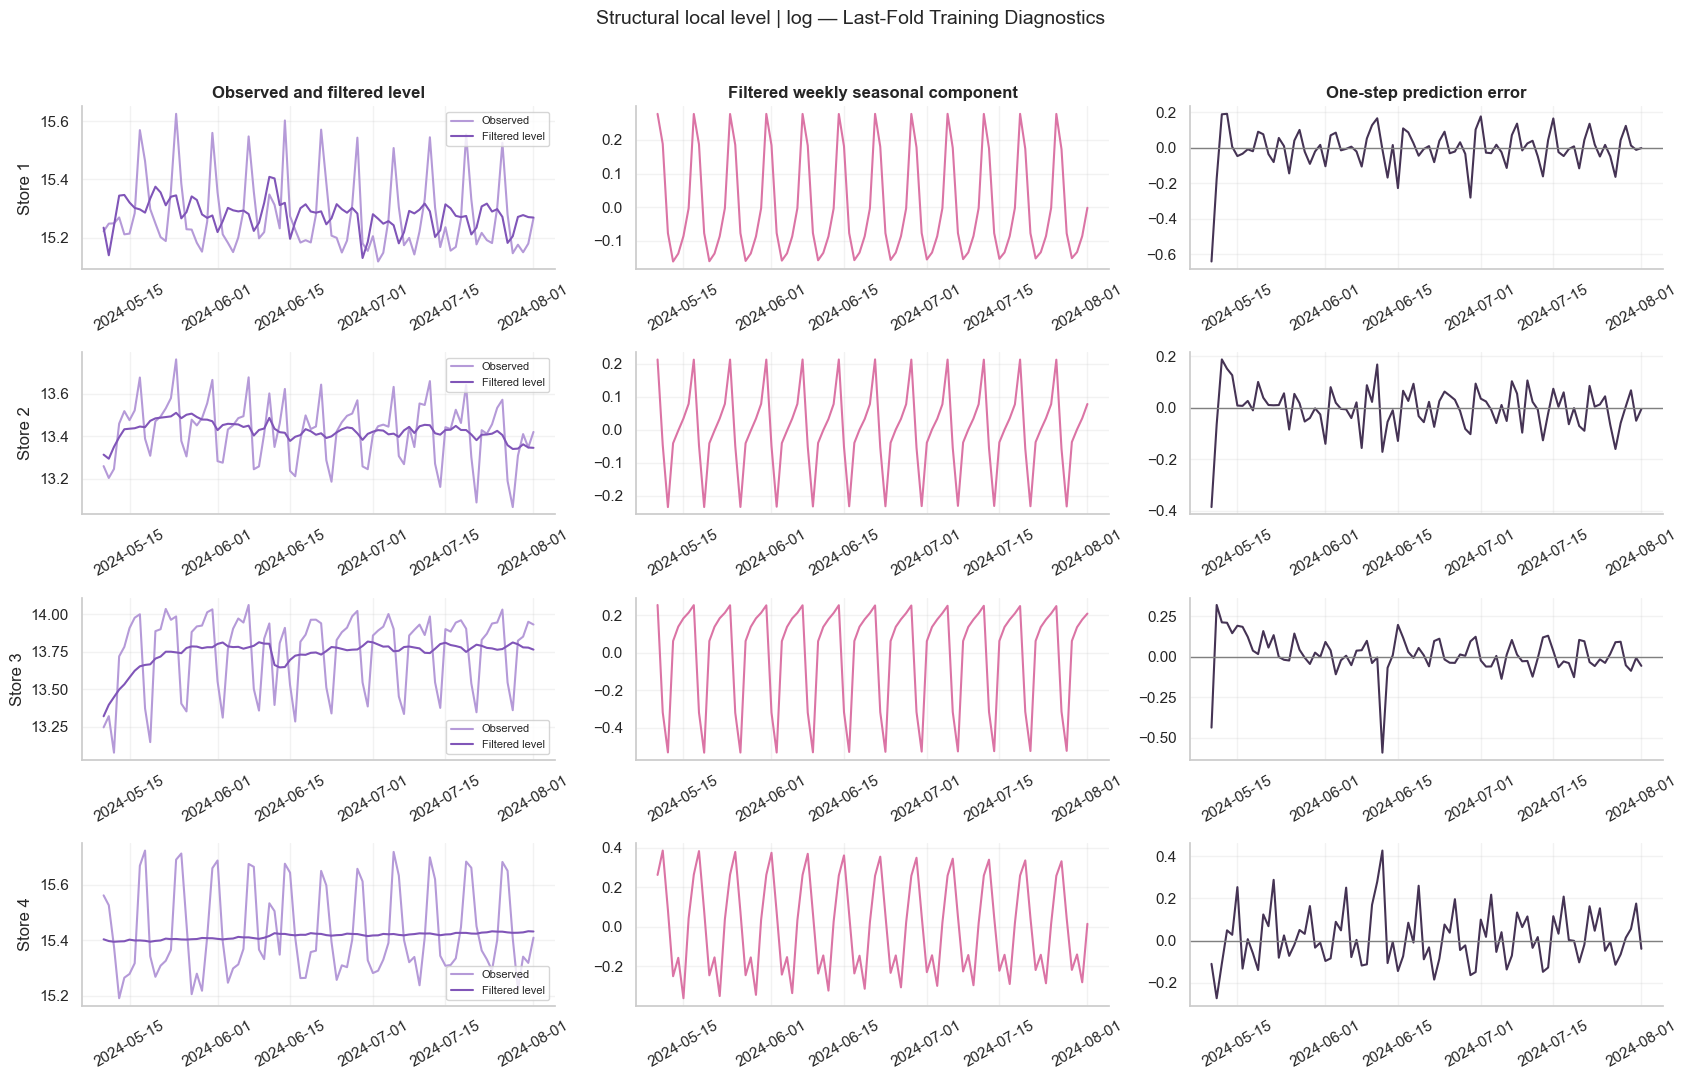

In [7]:
complete_structural = (
    state_space_summary.loc[state_space_summary["complete_cv"]]
    .sort_values("mean_WAPE_pct")
)

if complete_structural.empty:
    raise ValueError("No complete structural candidate.")

best_structural_name = complete_structural.index[0]
best_structural_spec = next(
    spec for spec in state_space_candidates
    if spec["model"] == best_structural_name
)

fig, axes = plt.subplots(
    len(store_series), 3,
    figsize=(17, 11),
    squeeze=False,
)

for row, store_id in enumerate(sorted(store_series)):
    fitted = state_space_last_fold_fits[
        (best_structural_name, store_id)
    ]
    train = fold_data[(last_fold, store_id)]["train"]

    observed = (
        np.log(train)
        if best_structural_spec["scale"] == "log"
        else train / 1_000_000
    )

    dates = train.index[-84:]
    n_show = len(dates)

    axes[row, 0].plot(
        dates, observed.iloc[-n_show:],
        color=COLORS["lavender"],
        label="Observed",
    )
    axes[row, 0].plot(
        dates,
        np.asarray(fitted.level.filtered)[-n_show:],
        color=COLORS["purple"],
        label="Filtered level",
    )
    axes[row, 0].set_ylabel(f"Store {store_id}")
    axes[row, 0].legend(fontsize=8)

    axes[row, 1].plot(
        dates,
        np.asarray(fitted.seasonal.filtered)[-n_show:],
        color=COLORS["pink"],
    )

    # Fittedvalues are one-step predictions, not filtered observations.
    innovations = observed - pd.Series(
        np.asarray(fitted.fittedvalues),
        index=train.index,
    )

    axes[row, 2].plot(
        dates,
        innovations.iloc[-n_show:],
        color=COLORS["dark"],
    )
    axes[row, 2].axhline(0, color="grey", linewidth=1)

    for ax in axes[row]:
        ax.tick_params(axis="x", rotation=30)

for column, title in enumerate([
    "Observed and filtered level",
    "Filtered weekly seasonal component",
    "One-step prediction error",
]):
    axes[0, column].set_title(title)

fig.suptitle(
    f"{best_structural_name} — Last-Fold Training Diagnostics",
    fontsize=14,
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Inspect variances across all stored last-fold fits.
variance_rows = []

for (model_name, store_id), fitted in state_space_last_fold_fits.items():
    for parameter, value in zip(
        fitted.model.param_names, np.asarray(fitted.params)
    ):
        if parameter.startswith("sigma2"):
            variance_rows.append({
                "model": model_name,
                "store_id": store_id,
                "parameter": parameter,
                "estimated_variance": value,
            })

state_variances = pd.DataFrame(variance_rows)

display(
    state_variances.pivot(
        index=["model", "store_id"],
        columns="parameter",
        values="estimated_variance",
    ).style.format("{:.6g}")
)

state_variances.to_csv(
    RESULTS_DIR / "state_space_last_fold_variances.csv",
    index=False,
)

In [8]:
%pip install prophet


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   -- ------------------------------------- 0.8/12.1 MB 4.2 MB/s eta 0:00:03
   ----- ---------------------------------- 1.6/12.1 MB 4.2 MB/s eta 0:00:03
   --------- ------------------------------ 2.9/12.1 MB 4.8 MB/s eta 0:00:02
   ------------ --------------------------- 3.9/12.1 MB 5.0 MB/s eta 0:00:02
   -------------- ------------------------- 4.5/12.1 MB 4.5 MB/s eta 0:00:02
   ------------------ --------------------- 5.5/12.1 MB 4.5 MB/s eta 0:00:02
   --------------------- ------------------ 6.6/12.1 MB 4.5 MB/s eta 0:00:02
   ----------------------- ---------------- 7.1/12.1 MB 4.3 MB/s eta 0:00:02
   ------------------------- -------------- 7.9/12.1 MB 4.3 MB/s eta 0:00:01
   --------------------------- ------------ 8.4/12.1 MB 4.2 MB/s eta 0:00:01
   ---------------------------- ----------- 8.7/12.1 MB 4.0 MB/s eta 0:00:01
   ------------------------------ --------- 9.2/12.1 MB 3.7 MB/s eta 0:00:01
   --

### Structural variance estimates

In the last-fold original-scale local-linear-trend fits, the estimated
slope-disturbance variances are approximately 10^-11 for all stores.
The stochastic slope is therefore effectively constant in these fits,
consistent with their similarity to deterministic-slope models.

This is a property of the estimated models, not evidence that the
underlying business trend never changes.

## 4. Prophet: Seasonality, Trend Flexibility, and Calendar Regressors

We compare additive and multiplicative weekly seasonality, two trend
changepoint prior scales, and configurations with or without additional
calendar regressors.

The calendar regressors indicate the first three and last three days
of each month. They are known in advance. Their relevance is a hypothesis
tested through validation, not an assumed business effect.

We disable daily and annual seasonality and use weekly Fourier order 3.
We fit the original target expressed in millions of source monetary units.

Every candidate generates the full 28-day horizon from the same origins.
Validation targets are not used for fitting, changepoint selection, or updates.
Uncertainty simulation is disabled for this point-forecast comparison.

The no-regressor candidates still contain Prophet's trend and weekly
seasonality; “without regressors” means without additional calendar columns.

In [9]:
from prophet import Prophet

prophet_candidates = [
    {
        "model": (
            f"Prophet {mode} | cps={cps} | calendar={calendar}"
        ),
        "seasonality_mode": mode,
        "changepoint_prior_scale": cps,
        "calendar": calendar,
    }
    for mode in ["additive", "multiplicative"]
    for cps in [0.01, 0.1]
    for calendar in [False, True]
]


def add_calendar_regressors(frame):
    result = frame.copy()
    dates = pd.DatetimeIndex(result["ds"])

    result["month_start_3d"] = (dates.day <= 3).astype(float)
    result["month_end_3d"] = (
        dates.days_in_month - dates.day < 3
    ).astype(float)

    return result


def fit_prophet_forecast(train, future_dates, spec):
    history = pd.DataFrame({
        "ds": train.index,
        "y": train.to_numpy() / 1_000_000,
    })
    future = pd.DataFrame({"ds": future_dates})

    if spec["calendar"]:
        history = add_calendar_regressors(history)
        future = add_calendar_regressors(future)

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        model = Prophet(
            growth="linear",
            seasonality_mode=spec["seasonality_mode"],
            changepoint_prior_scale=spec["changepoint_prior_scale"],
            seasonality_prior_scale=10.0,
            weekly_seasonality=False,
            yearly_seasonality=False,
            daily_seasonality=False,
            n_changepoints=15,
            changepoint_range=0.8,
            uncertainty_samples=0,
        )

        model.add_seasonality(
            name="weekly",
            period=7,
            fourier_order=3,
        )

        if spec["calendar"]:
            for column in ["month_start_3d", "month_end_3d"]:
                model.add_regressor(
                    column,
                    prior_scale=1.0,
                    standardize=False,
                    mode="additive",
                )

        model.fit(history, seed=SEED)
        forecast = model.predict(future)
        prediction = forecast["yhat"].to_numpy() * 1_000_000

    if (
        prediction.shape != (len(future_dates),)
        or not np.isfinite(prediction).all()
    ):
        raise ValueError("Invalid Prophet forecast.")

    warning_text = " | ".join(
        f"{type(w.message).__name__}: {w.message}"
        for w in caught
    )

    return model, prediction, warning_text

In [10]:
prophet_score_rows = []
prophet_prediction_parts = []
prophet_issue_rows = []
prophet_last_fold_fits = {}

for number, spec in enumerate(prophet_candidates, start=1):
    print(f"{number}/{len(prophet_candidates)}: {spec['model']}")

    for (fold, store_id), data in fold_data.items():
        try:
            fitted, prediction, warning_text = fit_prophet_forecast(
                data["train"],
                data["valid"].index,
                spec,
            )
            metrics = forecast_metrics(
                data["valid"].to_numpy(), prediction
            )

        except (
            ValueError, RuntimeError, FloatingPointError,
            np.linalg.LinAlgError,
        ) as error:
            prophet_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "failed",
                "message": str(error),
            })
            continue

        prophet_score_rows.append({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            **metrics,
        })

        prophet_prediction_parts.append(pd.DataFrame({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            "date": data["valid"].index,
            "actual": data["valid"].to_numpy(),
            "prediction": prediction,
        }))

        if warning_text:
            prophet_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "warning",
                "message": warning_text,
            })

        if fold == last_fold:
            prophet_last_fold_fits[(spec["model"], store_id)] = fitted

prophet_scores = pd.DataFrame(prophet_score_rows)
prophet_predictions = (
    pd.concat(prophet_prediction_parts, ignore_index=True)
    if prophet_prediction_parts else pd.DataFrame()
)
prophet_issues = pd.DataFrame(
    prophet_issue_rows,
    columns=["model", "fold", "store_id", "status", "message"],
)

display(prophet_issues)

prophet_scores.to_csv(
    RESULTS_DIR / "prophet_cv_scores.csv", index=False
)
prophet_predictions.to_csv(
    RESULTS_DIR / "prophet_cv_predictions.csv", index=False
)
prophet_issues.to_csv(
    RESULTS_DIR / "prophet_fit_issues.csv", index=False
)

if prophet_scores.empty:
    raise RuntimeError("All Prophet fits failed; inspect the issue table.")

1/8: Prophet additive | cps=0.01 | calendar=False


14:58:08 - cmdstanpy - INFO - Chain [1] start processing
14:58:08 - cmdstanpy - INFO - Chain [1] done processing
14:58:09 - cmdstanpy - INFO - Chain [1] start processing
14:58:09 - cmdstanpy - INFO - Chain [1] done processing
14:58:09 - cmdstanpy - INFO - Chain [1] start processing
14:58:09 - cmdstanpy - INFO - Chain [1] done processing
14:58:10 - cmdstanpy - INFO - Chain [1] start processing
14:58:10 - cmdstanpy - INFO - Chain [1] done processing
14:58:10 - cmdstanpy - INFO - Chain [1] start processing
14:58:10 - cmdstanpy - INFO - Chain [1] done processing
14:58:10 - cmdstanpy - INFO - Chain [1] start processing
14:58:10 - cmdstanpy - INFO - Chain [1] done processing
14:58:11 - cmdstanpy - INFO - Chain [1] start processing
14:58:11 - cmdstanpy - INFO - Chain [1] done processing
14:58:11 - cmdstanpy - INFO - Chain [1] start processing
14:58:11 - cmdstanpy - INFO - Chain [1] done processing
14:58:12 - cmdstanpy - INFO - Chain [1] start processing
14:58:12 - cmdstanpy - INFO - Chain [1]

2/8: Prophet additive | cps=0.01 | calendar=True


14:58:15 - cmdstanpy - INFO - Chain [1] start processing
14:58:15 - cmdstanpy - INFO - Chain [1] done processing
14:58:15 - cmdstanpy - INFO - Chain [1] start processing
14:58:15 - cmdstanpy - INFO - Chain [1] done processing
14:58:15 - cmdstanpy - INFO - Chain [1] start processing
14:58:15 - cmdstanpy - INFO - Chain [1] done processing
14:58:16 - cmdstanpy - INFO - Chain [1] start processing
14:58:16 - cmdstanpy - INFO - Chain [1] done processing
14:58:16 - cmdstanpy - INFO - Chain [1] start processing
14:58:16 - cmdstanpy - INFO - Chain [1] done processing
14:58:16 - cmdstanpy - INFO - Chain [1] start processing
14:58:16 - cmdstanpy - INFO - Chain [1] done processing
14:58:17 - cmdstanpy - INFO - Chain [1] start processing
14:58:17 - cmdstanpy - INFO - Chain [1] done processing
14:58:17 - cmdstanpy - INFO - Chain [1] start processing
14:58:17 - cmdstanpy - INFO - Chain [1] done processing
14:58:17 - cmdstanpy - INFO - Chain [1] start processing
14:58:17 - cmdstanpy - INFO - Chain [1]

3/8: Prophet additive | cps=0.1 | calendar=False


14:58:20 - cmdstanpy - INFO - Chain [1] start processing
14:58:20 - cmdstanpy - INFO - Chain [1] done processing
14:58:20 - cmdstanpy - INFO - Chain [1] start processing
14:58:20 - cmdstanpy - INFO - Chain [1] done processing
14:58:20 - cmdstanpy - INFO - Chain [1] start processing
14:58:20 - cmdstanpy - INFO - Chain [1] done processing
14:58:21 - cmdstanpy - INFO - Chain [1] start processing
14:58:21 - cmdstanpy - INFO - Chain [1] done processing
14:58:21 - cmdstanpy - INFO - Chain [1] start processing
14:58:21 - cmdstanpy - INFO - Chain [1] done processing
14:58:21 - cmdstanpy - INFO - Chain [1] start processing
14:58:21 - cmdstanpy - INFO - Chain [1] done processing
14:58:22 - cmdstanpy - INFO - Chain [1] start processing
14:58:22 - cmdstanpy - INFO - Chain [1] done processing
14:58:22 - cmdstanpy - INFO - Chain [1] start processing
14:58:22 - cmdstanpy - INFO - Chain [1] done processing
14:58:22 - cmdstanpy - INFO - Chain [1] start processing
14:58:22 - cmdstanpy - INFO - Chain [1]

... (7 outputs left out)

14:58:41 - cmdstanpy - INFO - Chain [1] start processing
14:58:41 - cmdstanpy - INFO - Chain [1] done processing
14:58:41 - cmdstanpy - INFO - Chain [1] start processing
14:58:41 - cmdstanpy - INFO - Chain [1] done processing
14:58:42 - cmdstanpy - INFO - Chain [1] start processing
14:58:42 - cmdstanpy - INFO - Chain [1] done processing
14:58:42 - cmdstanpy - INFO - Chain [1] start processing
14:58:42 - cmdstanpy - INFO - Chain [1] done processing
14:58:42 - cmdstanpy - INFO - Chain [1] start processing
14:58:42 - cmdstanpy - INFO - Chain [1] done processing
14:58:43 - cmdstanpy - INFO - Chain [1] start processing
14:58:43 - cmdstanpy - INFO - Chain [1] done processing
14:58:43 - cmdstanpy - INFO - Chain [1] start processing
14:58:43 - cmdstanpy - INFO - Chain [1] done processing
14:58:43 - cmdstanpy - INFO - Chain [1] start processing
14:58:43 - cmdstanpy - INFO - Chain [1] done processing
14:58:44 - cmdstanpy - INFO - Chain [1] start processing
14:58:44 - cmdstanpy - INFO - Chain [1]

8/8: Prophet multiplicative | cps=0.1 | calendar=True


14:58:46 - cmdstanpy - INFO - Chain [1] start processing
14:58:46 - cmdstanpy - INFO - Chain [1] done processing
14:58:47 - cmdstanpy - INFO - Chain [1] start processing
14:58:47 - cmdstanpy - INFO - Chain [1] done processing
14:58:47 - cmdstanpy - INFO - Chain [1] start processing
14:58:47 - cmdstanpy - INFO - Chain [1] done processing
14:58:48 - cmdstanpy - INFO - Chain [1] start processing
14:58:48 - cmdstanpy - INFO - Chain [1] done processing
14:58:48 - cmdstanpy - INFO - Chain [1] start processing
14:58:48 - cmdstanpy - INFO - Chain [1] done processing
14:58:48 - cmdstanpy - INFO - Chain [1] start processing
14:58:48 - cmdstanpy - INFO - Chain [1] done processing
14:58:49 - cmdstanpy - INFO - Chain [1] start processing
14:58:49 - cmdstanpy - INFO - Chain [1] done processing
14:58:49 - cmdstanpy - INFO - Chain [1] start processing
14:58:49 - cmdstanpy - INFO - Chain [1] done processing
14:58:49 - cmdstanpy - INFO - Chain [1] start processing
14:58:49 - cmdstanpy - INFO - Chain [1]

,model,fold,store_id,status,message


,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds,complete_cv
model,,,,,
Prophet additive | cps=0.1 | calendar=False,7.818,13.508,4.020,16,True
Prophet multiplicative | cps=0.1 | calendar=False,8.097,13.782,3.408,16,True
Prophet additive | cps=0.1 | calendar=True,8.269,13.664,3.916,16,True
Prophet multiplicative | cps=0.1 | calendar=True,8.579,13.786,3.047,16,True
Prophet additive | cps=0.01 | calendar=False,9.040,19.364,1.676,16,True
Prophet multiplicative | cps=0.01 | calendar=False,9.624,20.068,1.234,16,True
Prophet additive | cps=0.01 | calendar=True,9.673,19.536,1.546,16,True
Prophet multiplicative | cps=0.01 | calendar=True,10.180,20.067,1.613,16,True


,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds
model,,,,
Prophet additive | cps=0.1 | calendar=False,7.818,13.508,4.020,16
SARIMAX log | annual K=1,8.038,16.673,-4.229,16
SARIMAX log | annual K=0,8.046,20.465,-0.952,16
"SARIMA(1,0,0)(0,1,1,7) | log",8.046,20.465,-0.952,16
Prophet multiplicative | cps=0.1 | calendar=False,8.097,13.782,3.408,16
"SARIMA(1,0,0)(0,1,1,7) | original",8.121,20.009,-0.408,16
Prophet additive | cps=0.1 | calendar=True,8.269,13.664,3.916,16
Prophet multiplicative | cps=0.1 | calendar=True,8.579,13.786,3.047,16
Prophet additive | cps=0.01 | calendar=False,9.040,19.364,1.676,16


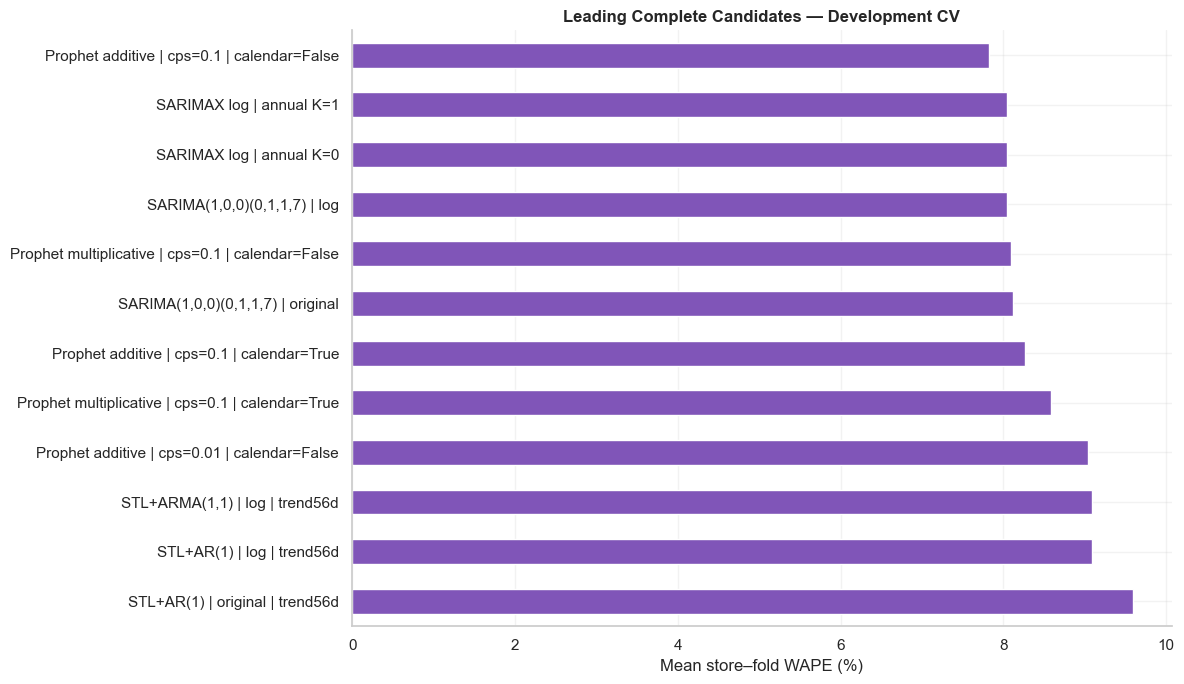

In [11]:
prophet_summary = (
    prophet_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
)

prophet_summary["complete_cv"] = (
    prophet_summary["evaluated_store_folds"].eq(len(fold_data))
)

display(
    prophet_summary.sort_values(
        ["complete_cv", "mean_WAPE_pct"],
        ascending=[False, True],
    )
)

combined_scores = pd.concat(
    [
        classical_scores,
        fourier_scores,
        state_space_scores,
        prophet_scores,
    ],
    ignore_index=True,
)

assert not combined_scores.duplicated(
    ["model", "fold", "store_id"]
).any()

combined_summary = (
    combined_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
)

complete_combined = (
    combined_summary.loc[
        combined_summary["evaluated_store_folds"].eq(len(fold_data))
    ]
    .sort_values("mean_WAPE_pct")
)

display(complete_combined.head(15))

complete_combined.head(12)["mean_WAPE_pct"].sort_values().plot.barh(
    figsize=(12, 7),
    color=COLORS["purple"],
)

plt.gca().invert_yaxis()
plt.title("Leading Complete Candidates — Development CV")
plt.xlabel("Mean store–fold WAPE (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

combined_summary.to_csv(
    RESULTS_DIR / "combined_cv_summary.csv"
)

### Prophet findings

The leading Prophet candidate uses additive weekly seasonality,
changepoint_prior_scale=0.1, and no additional calendar regressors.
It achieves mean WAPE of 7.818%, compared with 8.046% for the leading
classical SARIMA.

The improvement is modest at 0.228 percentage points. However, its
worst store–fold WAPE is lower, at 13.508% versus 20.465%.
Its mean signed bias is +4.020%, indicating average overforecasting
under our bias metric.

Within each tested seasonality/prior combination, adding month-start
and month-end regressors increases mean WAPE. These particular calendar
features do not improve the tested forecasts.

The larger changepoint prior scale performs better in this grid.
This supports greater trend flexibility within the tested configurations,
not a general rule that more flexibility is always preferable.

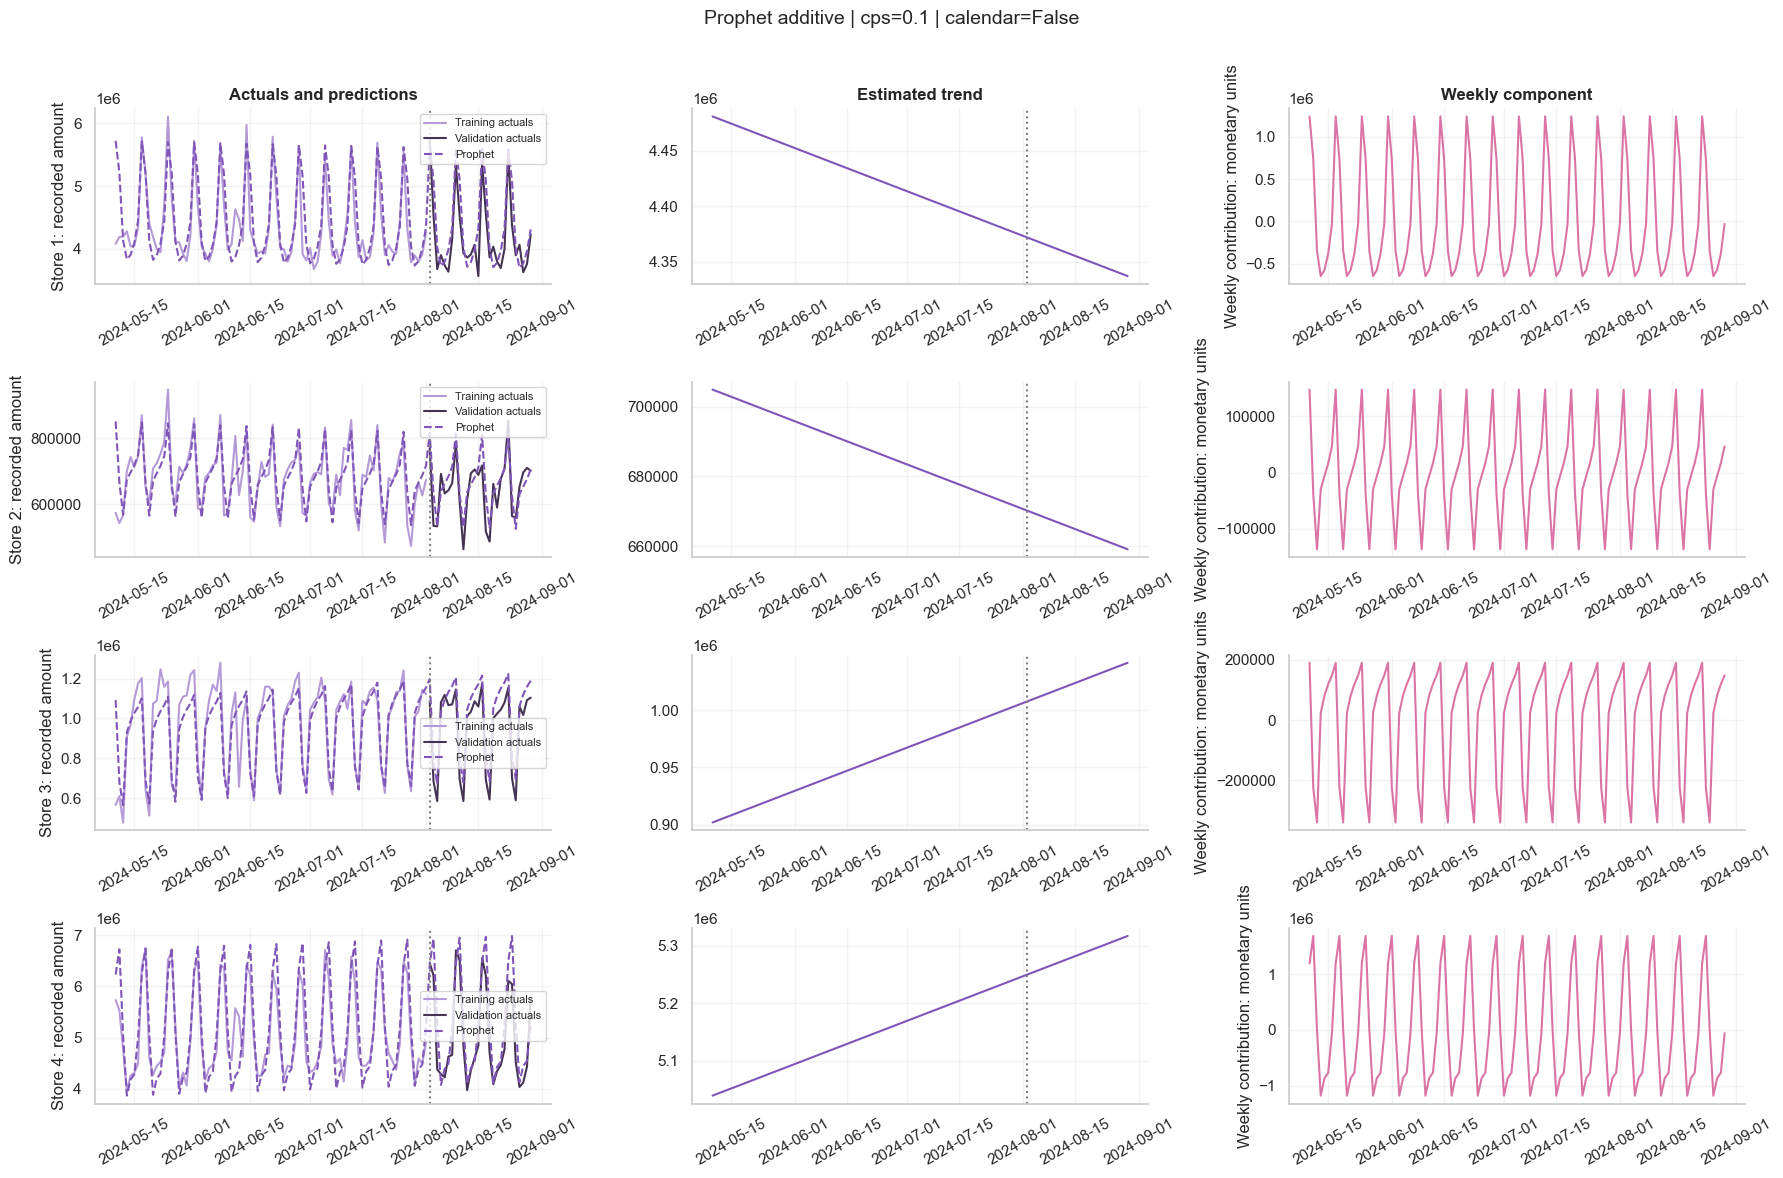

store_id,1,2,3,4
model,,,,
Prophet additive | cps=0.1 | calendar=False,8.229,7.020,7.906,8.115
"SARIMA(1,0,0)(0,1,1,7) | log",6.670,6.465,13.489,5.561
SARIMAX log | annual K=1,5.951,6.580,10.879,8.741
Seasonal naive,9.794,9.397,10.300,9.597


In [12]:
complete_prophet = (
    prophet_summary.loc[prophet_summary["complete_cv"]]
    .sort_values("mean_WAPE_pct")
)

if complete_prophet.empty:
    raise ValueError("No complete Prophet candidate.")

best_prophet_name = complete_prophet.index[0]

best_prophet_spec = next(
    spec for spec in prophet_candidates
    if spec["model"] == best_prophet_name
)

fig, axes = plt.subplots(
    len(store_series), 3,
    figsize=(18, 12),
    squeeze=False,
)

for row, store_id in enumerate(sorted(store_series)):
    model = prophet_last_fold_fits[(best_prophet_name, store_id)]
    data = fold_data[(last_fold, store_id)]
    train, valid = data["train"], data["valid"]

    display_dates = train.index[-84:].append(valid.index)
    future = pd.DataFrame({"ds": display_dates})

    if best_prophet_spec["calendar"]:
        future = add_calendar_regressors(future)

    components = model.predict(future)

    axes[row, 0].plot(
        train.tail(84).index, train.tail(84),
        color=COLORS["lavender"], label="Training actuals",
    )
    axes[row, 0].plot(
        valid.index, valid,
        color=COLORS["dark"], label="Validation actuals",
    )
    axes[row, 0].plot(
        components["ds"],
        components["yhat"] * 1_000_000,
        color=COLORS["purple"],
        linestyle="--",
        label="Prophet",
    )
    axes[row, 0].axvline(
        valid.index.min(), color="grey", linestyle=":"
    )
    axes[row, 0].set_ylabel(f"Store {store_id}: recorded amount")
    axes[row, 0].legend(fontsize=8)

    axes[row, 1].plot(
        components["ds"],
        components["trend"] * 1_000_000,
        color=COLORS["purple"],
    )
    axes[row, 1].axvline(
        valid.index.min(), color="grey", linestyle=":"
    )

    if best_prophet_spec["seasonality_mode"] == "additive":
        weekly = components["weekly"] * 1_000_000
        weekly_label = "Weekly contribution: monetary units"
    else:
        weekly = components["weekly"] * 100
        weekly_label = "Weekly contribution: % of trend"

    axes[row, 2].plot(
        components["ds"], weekly,
        color=COLORS["pink"],
    )
    axes[row, 2].set_ylabel(weekly_label)

    for ax in axes[row]:
        ax.tick_params(axis="x", rotation=30)

for column, title in enumerate([
    "Actuals and predictions", "Estimated trend", "Weekly component"
]):
    axes[0, column].set_title(title)

fig.suptitle(best_prophet_name, fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# CV errors by store, rather than last-fold plots alone.
reference_models = [
    best_prophet_name,
    "SARIMAX log | annual K=1",
    "SARIMA(1,0,0)(0,1,1,7) | log",
    "Seasonal naive",
]

display(
    combined_scores.loc[
        combined_scores["model"].isin(reference_models)
    ]
    .groupby(["model", "store_id"])["WAPE_pct"]
    .mean()
    .unstack("store_id")
)

## 5. Conclusions and Limitations

Prophet with additive weekly seasonality, changepoint_prior_scale=0.1,
and no additional regressors is the current CV leader at 7.818% WAPE.

Annual Fourier terms provide no clear mean-error improvement over the
SARIMA control. Two annual harmonics substantially worsen performance.

The best tested structural state-space model achieves 10.131% WAPE.
Additional trend components do not improve its validation performance.

We retain the leading Prophet and SARIMA/Fourier candidates for comparison
with ML and DL models. No final model is selected using holdout results.

All rankings use the same development folds, which have informed repeated
model choices. Small differences should therefore be interpreted cautiously.
The validation period also does not cover a complete annual cycle.

Predictors in this notebook are calendar-derived and known in advance.
We have not validated realized future prices, promotions, or weather as
available exogenous inputs.

The final holdout remains unopened.

In [13]:
prediction_columns = [
    "model", "fold", "store_id", "date", "actual", "prediction"
]

calendar_predictions = pd.concat(
    [
        fourier_predictions[prediction_columns],
        state_space_predictions[prediction_columns],
        prophet_predictions[prediction_columns],
    ],
    ignore_index=True,
)

calendar_scores = pd.concat(
    [fourier_scores, state_space_scores, prophet_scores],
    ignore_index=True,
)

assert not calendar_predictions.duplicated(
    ["model", "fold", "store_id", "date"]
).any()

assert calendar_predictions["date"].max() < TEST_START
assert np.isfinite(
    calendar_predictions[["actual", "prediction"]].to_numpy()
).all()

prediction_counts = calendar_predictions.groupby(
    ["model", "fold", "store_id"]
).size()

assert prediction_counts.eq(HORIZON).all()
assert len(prediction_counts) == len(calendar_scores)

assert (
    calendar_predictions
    .groupby(["fold", "store_id", "date"])["actual"]
    .nunique()
    .eq(1)
    .all()
)

calendar_predictions["error"] = (
    calendar_predictions["prediction"]
    - calendar_predictions["actual"]
)
calendar_predictions["absolute_error"] = (
    calendar_predictions["error"].abs()
)

calendar_predictions.to_csv(
    RESULTS_DIR / "calendar_state_space_cv_predictions.csv",
    index=False,
    date_format="%Y-%m-%d",
)

calendar_scores.to_csv(
    RESULTS_DIR / "calendar_state_space_cv_scores.csv",
    index=False,
)

combined_summary.to_csv(
    RESULTS_DIR / "combined_cv_summary.csv"
)

import prophet
import statsmodels

selection_record = {
    "status": "development comparison; final selection not frozen",
    "leading_candidate": complete_combined.index[0],
    "reference_candidates": reference_models,
    "forecast_horizon_days": HORIZON,
    "holdout_used": False,
    "versions": {
        "prophet": prophet.__version__,
        "statsmodels": statsmodels.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}

with (RESULTS_DIR / "calendar_selection.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(selection_record, file, ensure_ascii=False, indent=2)

print("Calendar, state-space, and Prophet CV results exported.")

Calendar, state-space, and Prophet CV results exported.
